# Gráficos do benchmark

Gera as figuras do artigo a partir de `resultados/*.csv` (saída do `analise.py`) e de `respostas_brutas/*.jsonl`.
As figuras são salvas em PDF (para o LaTeX) e PNG em `../../docs/latex/figuras/`.

Requer: `pip install pandas numpy matplotlib`. Rode o `analise.py` antes.

In [1]:
import glob, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

RES = "resultados"
RAW = "respostas_brutas"
OUT = "../../docs/latex/figuras"
os.makedirs(OUT, exist_ok=True)

# rótulos e ordem fixa (a cor segue o modelo, nunca a posição)
MODELOS = ["claude", "openai", "gemini", "gpt-oss-120b", "JURY"]
NOME = {"claude": "Claude Sonnet 5.5", "openai": "GPT-5.6-terra", "gemini": "Gemini 3.7 Flash",
        "gpt-oss-120b": "gpt-oss-120b", "JURY": "Júri"}
COR = {"claude": "#2a78d6", "openai": "#eb6834", "gemini": "#1baf7a", "gpt-oss-120b": "#eda100", "JURY": "#3d3d3a"}
MARCA = {"claude": "o", "openai": "s", "gemini": "D", "gpt-oss-120b": "^", "JURY": "P"}
DEFEITOS = ["ambiguity", "incompleteness", "non_verifiability", "inconsistency"]
NOME_DEF = {"none": "Nenhum", "ambiguity": "Ambiguidade", "incompleteness": "Incompletude",
            "non_verifiability": "Falta de\nverificabilidade", "inconsistency": "Inconsistência"}
AZUL = LinearSegmentedColormap.from_list("azul", ["#f4f8fd", "#2a78d6", "#0d3c73"])

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "figure.dpi": 150, "savefig.bbox": "tight",
})

from matplotlib.ticker import FuncFormatter, ScalarFormatter
VIRG = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))  # decimal com vírgula

def salvar(fig, nome):
    for a in fig.axes:
        for eixo in (a.xaxis, a.yaxis):
            if isinstance(eixo.get_major_formatter(), ScalarFormatter):
                eixo.set_major_formatter(VIRG)
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{nome}.{ext}", dpi=300)
    plt.show()

sens = pd.read_csv(f"{RES}/01_sensibilidade_por_defeito.csv")
spec = pd.read_csv(f"{RES}/02_especificidade_e_F1.csv")
queda = pd.read_csv(f"{RES}/03_queda_de_nota_no_criterio_afetado.csv")
rob = pd.read_csv(f"{RES}/06_robustez_a_mudancas_superficiais.csv")
raw = pd.DataFrame([json.loads(l) for f in glob.glob(f"{RAW}/*.jsonl") for l in open(f, encoding="utf-8")])
corpus = pd.read_csv("corpus_requisitos.csv")
print(len(raw), "respostas")

1200 respostas


## Figura 1 — Detecção exata do defeito injetado (RQ1, RQ4)

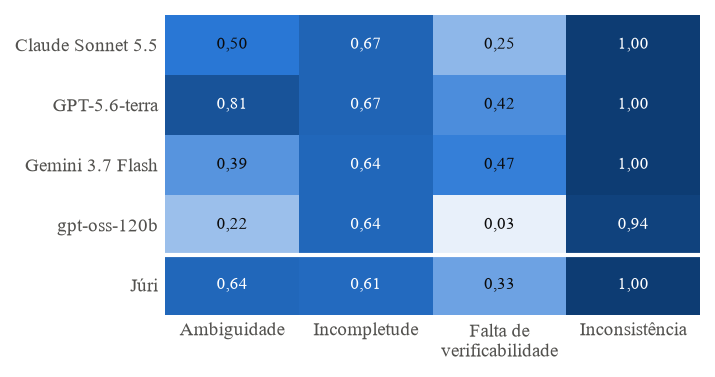

In [2]:
m = sens.pivot(index="model", columns="defect", values="exact_detection").loc[MODELOS, DEFEITOS]
fig, ax = plt.subplots(figsize=(4.6, 2.6))
ax.imshow(m.values, cmap=AZUL, vmin=0, vmax=1, aspect="auto")
ax.grid(False)
ax.set_xticks(range(4), [NOME_DEF[d] for d in DEFEITOS])
ax.set_yticks(range(len(MODELOS)), [NOME[x] for x in MODELOS])
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        v = m.values[i, j]
        ax.text(j, i, f"{v:.2f}".replace(".", ","), ha="center", va="center",
                color="white" if v > 0.55 else "#0b0b0b", fontsize=8)
ax.axhline(3.5, color="white", lw=2)  # separa o júri dos modelos
ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
salvar(fig, "fig1_deteccao")

## Figura 2 — Falsos positivos × falsos negativos (RQ1)

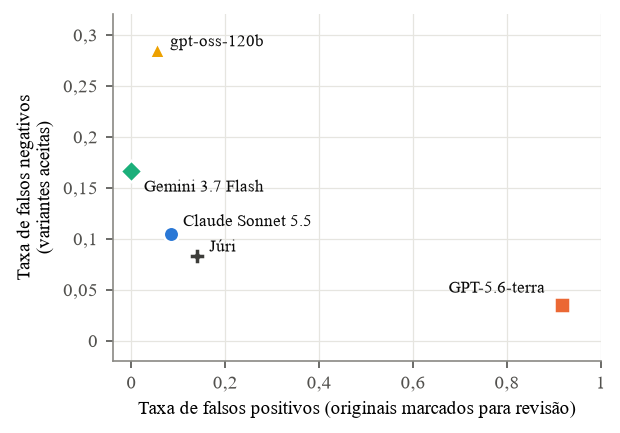

In [3]:
s = spec.set_index("model").loc[MODELOS]
fig, ax = plt.subplots(figsize=(4.2, 3.0))
desl = {"claude": (6, 4), "openai": (-8, 6), "gemini": (6, -10), "gpt-oss-120b": (6, 2), "JURY": (6, 2)}
for k in MODELOS:
    x, y = s.loc[k, "false_positive_rate"], s.loc[k, "false_negative_rate"]
    ax.scatter(x, y, s=55, color=COR[k], marker=MARCA[k], edgecolor="white", linewidth=1.2, zorder=3)
    ha = "right" if desl[k][0] < 0 else "left"
    ax.annotate(NOME[k], (x, y), textcoords="offset points", xytext=desl[k], ha=ha, fontsize=8, color="#0b0b0b")
ax.set_xlim(-0.04, 1.0); ax.set_ylim(-0.02, 0.32)
ax.set_xlabel("Taxa de falsos positivos (originais marcados para revisão)")
ax.set_ylabel("Taxa de falsos negativos\n(variantes aceitas)")
salvar(fig, "fig2_fp_fn")

## Figura 3 — Queda de nota no critério afetado, com IC 95% (RQ1, RQ4)

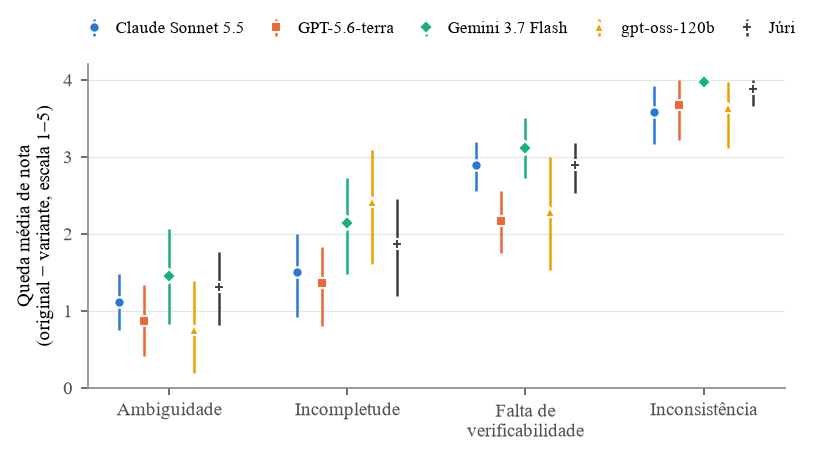

In [4]:
fig, ax = plt.subplots(figsize=(6.0, 2.8))
off = np.linspace(-0.28, 0.28, len(MODELOS))
for o, k in zip(off, MODELOS):
    d = queda[queda.model == k].set_index("defect").loc[DEFEITOS]
    x = np.arange(4) + o
    ax.errorbar(x, d.mean_drop, yerr=[d.mean_drop - d.drop_lo, d.drop_hi - d.mean_drop], fmt=MARCA[k],
                color=COR[k], ms=5, elinewidth=1.2, capsize=0, markeredgecolor="white", label=NOME[k])
ax.set_xticks(range(4), [NOME_DEF[d] for d in DEFEITOS])
ax.set_ylabel("Queda média de nota\n(original − variante, escala 1–5)")
ax.set_ylim(0, 4.2); ax.grid(axis="x", visible=False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.18), frameon=False, handletextpad=0.3, columnspacing=0.9)
salvar(fig, "fig3_queda_nota")

## Figura 4 — Efeito das perturbações comparado ao ruído entre repetições (RQ2, RQ3)

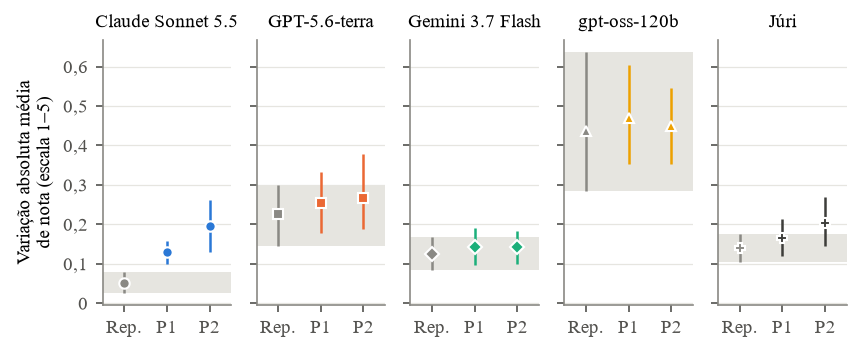

In [5]:
COMP = ["ruido_P0rep1_vs_P0rep2", "P0_vs_P1_formatacao", "P0_vs_P2_ordem_contexto"]
ROT = ["Rep.", "P1", "P2"]  # Rep. = ruído entre repetições; P1 = formatação; P2 = ordem do contexto
fig, axs = plt.subplots(1, len(MODELOS), figsize=(6.4, 2.3), sharey=True)
for ax, k in zip(axs, MODELOS):
    d = rob[rob.model == k].set_index("comparison").loc[COMP]
    y = d.mean_abs_score_change
    for i, c in enumerate(COMP):
        cor = "#8a8984" if i == 0 else COR[k]
        ax.errorbar(i, y[c], yerr=[[y[c] - d.loc[c, "mean_abs_score_change_lo"]], [d.loc[c, "mean_abs_score_change_hi"] - y[c]]],
                    fmt=MARCA[k], color=cor, ms=5, elinewidth=1.2, markeredgecolor="white")
    ax.axhspan(d.loc[COMP[0], "mean_abs_score_change_lo"], d.loc[COMP[0], "mean_abs_score_change_hi"], color="#e6e5e0", zorder=0, lw=0)
    ax.set_title(NOME[k]); ax.set_xticks(range(3), ROT); ax.set_xlim(-0.5, 2.5)
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel("Variação absoluta média\nde nota (escala 1–5)")
salvar(fig, "fig4_robustez")

## Figura 5 — Defeito injetado × defeito apontado (todas as respostas, 4 modelos)

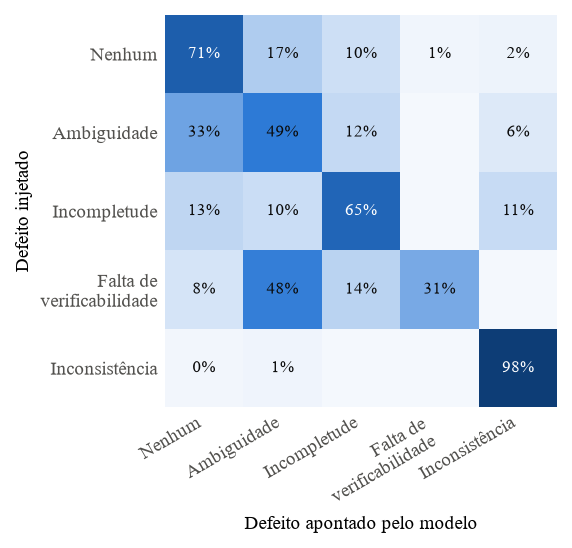

defect_type,none,ambiguity,incompleteness,non_verifiability,inconsistency
defeito_injetado,,,,,
none,170,41,23,2,4
ambiguity,79,118,29,0,14
incompleteness,31,25,157,0,27
non_verifiability,18,114,34,74,0
inconsistency,1,3,0,0,236


In [6]:
CL = ["none"] + DEFEITOS
r = raw.merge(corpus[["id_requisito", "defeito_injetado"]], left_on="requirement_id", right_on="id_requisito")
r["defeito_injetado"] = r["defeito_injetado"].fillna("none").replace({"": "none"})
ct = pd.crosstab(r.defeito_injetado, r.defect_type).reindex(index=CL, columns=CL, fill_value=0)
pct = ct.div(ct.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(4.4, 3.4))
ax.imshow(pct.values, cmap=AZUL, vmin=0, vmax=1)
ax.grid(False)
nomes = [NOME_DEF[c] for c in CL]
ax.set_xticks(range(5), nomes, rotation=30, ha="right"); ax.set_yticks(range(5), nomes)
ax.set_xlabel("Defeito apontado pelo modelo"); ax.set_ylabel("Defeito injetado")
for i in range(5):
    for j in range(5):
        v = pct.values[i, j]
        if ct.values[i, j]:
            ax.text(j, i, f"{100*v:.0f}%", ha="center", va="center", color="white" if v > 0.55 else "#0b0b0b", fontsize=8)
ax.tick_params(length=0)
for s_ in ax.spines.values(): s_.set_visible(False)
salvar(fig, "fig5_confusao")
ct